<a href="https://colab.research.google.com/github/pavipandi321-lgtm/CAO_Matrix_Transpose/blob/main/CAO_Matrix_Transpose_Project_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Title: Performance Analysis of CPU and GPU for Matrix Transposition**

**Team: Pavithra, Devaguru P Y**

In [ ]:
#1
import time # confirming the hardware
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from numba import njit, cuda, float32
GPU_AVAILABLE = cuda.is_available()
print("NumPy version:", np.__version__)
print("GPU available:", GPU_AVAILABLE)
if GPU_AVAILABLE:
    try:
        gpu = cuda.get_current_device()
        print("GPU:", gpu.name)
        print("GPU compute capability:", gpu.compute_capability)
        print("GPU max threads per block:", gpu.MAX_THREADS_PER_BLOCK)
    except Exception as e:
        print("GPU information error:", e)
cpu = psutil.cpu_freq()
print("CPU logical cores:", psutil.cpu_count(logical=True))
print("CPU physical cores:", psutil.cpu_count(logical=False))
if cpu:
    print("CPU frequency (MHz):", round(cpu.current, 2))

NumPy version: 2.4.6
GPU available: True
GPU: Tesla T4
GPU compute capability: ComputeCapability(major=7, minor=5)
GPU max threads per block: 1024
CPU logical cores: 2
CPU physical cores: 1
CPU frequency (MHz): 2000.19


Matrix transposition demonstration using NumPy:

In [ ]:
#2
import numpy as np # 2x3
A_small = np.array([[1, 2, 3],
                    [4, 5, 6]], dtype=np.float32)
print("Original matrix:")
print(A_small)
print("\nNumPy transpose:")
print(A_small.T)
print("\nExpected:")
print(np.array([[1, 4],
                [2, 5],
                [3, 6]], dtype=np.float32))

Original matrix:
[[1. 2. 3.]
 [4. 5. 6.]]

NumPy transpose:
[[1. 4.]
 [2. 5.]
 [3. 6.]]

Expected:
[[1. 4.]
 [2. 5.]
 [3. 6.]]


**2. Architecture Idea:**

CPU implementation:

In [ ]:
#3
import numpy as np
import time
from numba import njit
@njit  # tells Numba to compile the function so that it can run faster
def transpose_cpu(A, B):
    rows, cols = A.shape
    for i in range(rows):
        for j in range(cols):
            B[j, i] = A[i, j]  # transpose
def run_cpu(A):
    B = np.empty((A.shape[1], A.shape[0]), dtype=A.dtype)
    transpose_cpu(A, B)
    start = time.perf_counter()
    transpose_cpu(A, B)
    elapsed = time.perf_counter() - start  # measuring CPU execution time
    return B, elapsed

GPU version of matrix transposition:

In [ ]:
#4
from numba import cuda
GPU_AVAILABLE = cuda.is_available()
if GPU_AVAILABLE:
    @cuda.jit # tells Numba to compile the function for execution on an GPU
    def transpose_gpu_naive(A, B):
        col, row = cuda.grid(2)
        if row < A.shape[0] and col < A.shape[1]:
            B[col, row] = A[row, col]
else:
    transpose_gpu_naive = None
print("GPU available:", GPU_AVAILABLE)

GPU available: True


Defining the GPU function:

In [ ]:
#5 titling
if GPU_AVAILABLE:
    TILE = 16 # each tile has 16 rows and 16 columns
    @cuda.jit
    def transpose_gpu_tiled(A, B):
        tile = cuda.shared.array((16, 17), dtype=float32)
        tx = cuda.threadIdx.x
        ty = cuda.threadIdx.y
        row = cuda.blockIdx.y * 16 + ty
        col = cuda.blockIdx.x * 16 + tx
        if row < A.shape[0] and col < A.shape[1]:
            tile[ty, tx] = A[row, col]
        cuda.syncthreads()
        out_row = cuda.blockIdx.x * 16 + ty
        out_col = cuda.blockIdx.y * 16 + tx
        if out_row < B.shape[0] and out_col < B.shape[1]:
            B[out_row, out_col] = tile[tx, ty]
else:
    transpose_gpu_tiled = None

In [ ]:
#6
import numpy as np
import math
import time
from numba import cuda
GPU_AVAILABLE = cuda.is_available()
def run_gpu(A, kernel, block=(16, 16)):
    if not GPU_AVAILABLE:
        return None, np.nan
    d_A = cuda.to_device(A)
    B = np.empty(
        (A.shape[1], A.shape[0]),
        dtype=A.dtype
    )
    d_B = cuda.device_array_like(B)
    grid = (
        math.ceil(A.shape[1] / block[0]),
        math.ceil(A.shape[0] / block[1])
    )
    kernel[grid, block](d_A, d_B)
    cuda.synchronize()
    start = time.perf_counter()
    kernel[grid, block](d_A, d_B)
    cuda.synchronize()
    elapsed = time.perf_counter() - start
    d_B.copy_to_host(B)
    return B, elapsed

In [ ]:
#7
import numpy as np
import time
from numba import njit, cuda
@njit
def transpose_cpu(A, B):
    rows, cols = A.shape
    for i in range(rows):
        for j in range(cols):
            B[j, i] = A[i, j]
def run_cpu(A):
    B = np.empty((A.shape[1], A.shape[0]), dtype=A.dtype)
    transpose_cpu(A, B)
    start = time.perf_counter()
    transpose_cpu(A, B)
    elapsed = time.perf_counter() - start
    return B, elapsed
A = np.random.rand(256, 256).astype(np.float32)
B_cpu, cpu_time = run_cpu(A)
print("CPU correct:", np.allclose(B_cpu, A.T))
print("CPU time:", cpu_time, "seconds")
if cuda.is_available():
    B_gpu, gpu_time = run_gpu(A, transpose_gpu_naive)
    print("GPU correct:", np.allclose(B_gpu, A.T))
    print("GPU time:", gpu_time, "seconds")
else:
    print("GPU test skipped because no GPU is available.")

CPU correct: True
CPU time: 0.0002051260000826005 seconds
GPU correct: True
GPU time: 7.877500001995941e-05 seconds


**3. Main benchmark**

We test several matrix sizes. For each size we record CPU time, GPU time, and speedup.

In [ ]:
#8
import numpy as np
import pandas as pd
sizes = [256, 512, 1024, 2048]
results = []
for N in sizes:
    print("Testing matrix size:", N, "x", N)
    A = np.random.rand(N, N).astype(np.float32)
    B_cpu, t_cpu = run_cpu(A)
    if GPU_AVAILABLE:
        B_gpu, t_gpu = run_gpu(A, transpose_gpu_naive)
        correct = np.allclose(B_cpu, B_gpu)
        speedup = t_cpu / t_gpu if t_gpu > 0 else np.nan
    else:
        t_gpu = np.nan
        speedup = np.nan
        correct = True
    results.append({
        "Matrix Size": f"{N}x{N}",
        "N": N,
        "CPU Time (s)": t_cpu,
        "GPU Naive Time (s)": t_gpu,
        "Speedup": speedup,
        "Correct": correct
    })
results_df = pd.DataFrame(results)
results_df

Testing matrix size: 256 x 256
Testing matrix size: 512 x 512
Testing matrix size: 1024 x 1024
Testing matrix size: 2048 x 2048


,Matrix Size,N,CPU Time (s),GPU Naive Time (s),Speedup,Correct
0,256x256,256,0.000236,0.000173,1.366695,True
1,512x512,512,0.001114,0.000080,13.844843,True
2,1024x1024,1024,0.005139,0.000126,40.817601,True
3,2048x2048,2048,0.020647,0.000357,57.906174,True


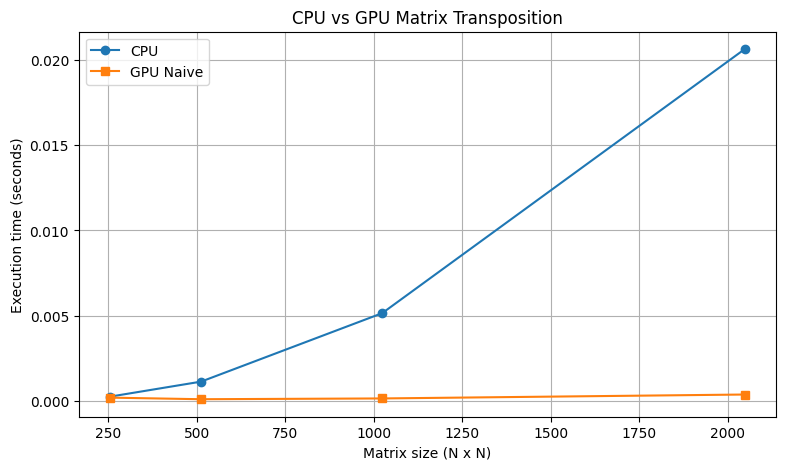

In [ ]:
#9
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.plot(
    results_df["N"],
    results_df["CPU Time (s)"],
    marker="o",
    label="CPU"
)
plt.plot(
    results_df["N"],
    results_df["GPU Naive Time (s)"],
    marker="s",
    label="GPU Naive"
)
plt.xlabel("Matrix size (N x N)")
plt.ylabel("Execution time (seconds)")
plt.title("CPU vs GPU Matrix Transposition")
plt.legend()
plt.grid(True)
plt.show()

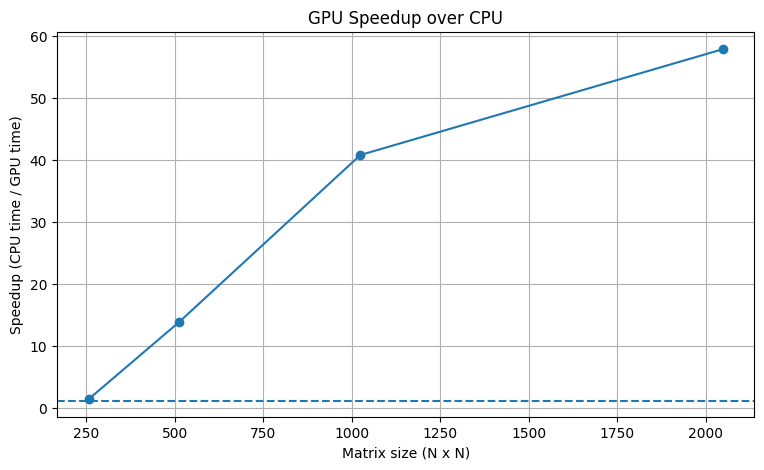

In [ ]:
#10
if GPU_AVAILABLE:
    plt.figure(figsize=(9,5))
    plt.plot(results_df["N"], results_df["Speedup"], marker="o")
    plt.axhline(1, linestyle="--")
    plt.xlabel("Matrix size (N x N)")
    plt.ylabel("Speedup (CPU time / GPU time)")
    plt.title("GPU Speedup over CPU")
    plt.grid(True)
    plt.show()
else:
    print("Speedup plot skipped because GPU is unavailable.")

**4. GPU optimization: naive vs tiled/shared memory**

In [ ]:
#11
TILE = 16
if GPU_AVAILABLE:
    @cuda.jit
    def transpose_gpu_tiled(A, B):
        tile = cuda.shared.array((16, 17), dtype=float32)
        tx = cuda.threadIdx.x
        ty = cuda.threadIdx.y
        row = cuda.blockIdx.y * 16 + ty
        col = cuda.blockIdx.x * 16 + tx
        if row < A.shape[0] and col < A.shape[1]:
            tile[ty, tx] = A[row, col]
        cuda.syncthreads()
        out_row = cuda.blockIdx.x * 16 + ty
        out_col = cuda.blockIdx.y * 16 + tx
        if out_row < B.shape[0] and out_col < B.shape[1]:
            B[out_row, out_col] = tile[tx, ty]
    print("Improved tiled GPU kernel ready.")

Improved tiled GPU kernel ready.


,N,GPU Naive (s),GPU Tiled (s),Tiled Speedup
0,512,0.000089,0.000081,1.110041
1,1024,0.000124,0.000106,1.173510
2,2048,0.000355,0.000268,1.324678


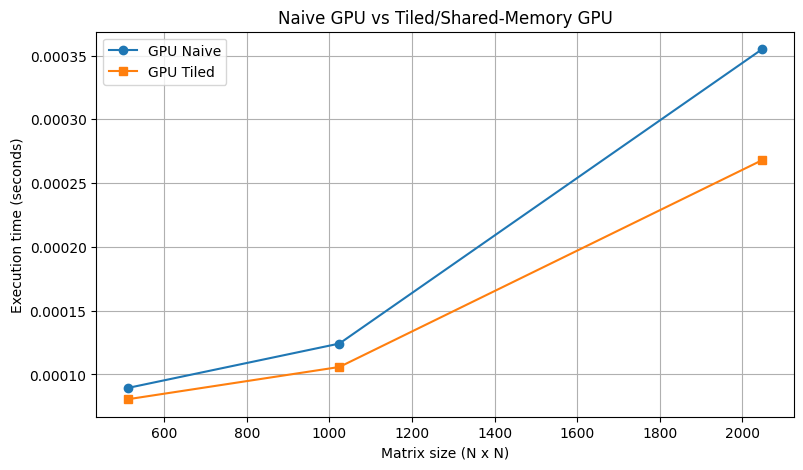

In [ ]:
#12
tile_results = []
if GPU_AVAILABLE:
    for N in [512, 1024, 2048]:
        A = np.random.rand(N, N).astype(np.float32)
        _, t_naive = run_gpu(A, transpose_gpu_naive, block=(16,16))
        _, t_tiled = run_gpu(A, transpose_gpu_tiled, block=(16,16))
        tile_results.append({
            "N": N,
            "GPU Naive (s)": t_naive,
            "GPU Tiled (s)": t_tiled,
            "Tiled Speedup": t_naive/t_tiled if t_tiled > 0 else np.nan
        })
    tile_df = pd.DataFrame(tile_results)
    display(tile_df)
    plt.figure(figsize=(9,5))
    plt.plot(tile_df["N"], tile_df["GPU Naive (s)"], marker="o", label="GPU Naive")
    plt.plot(tile_df["N"], tile_df["GPU Tiled (s)"], marker="s", label="GPU Tiled")
    plt.xlabel("Matrix size (N x N)")
    plt.ylabel("Execution time (seconds)")
    plt.title("Naive GPU vs Tiled/Shared-Memory GPU")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("GPU optimization section skipped because no GPU is available.")

**5. Host → Device transfer**

GPU computation can be fast, but moving data from CPU RAM to GPU VRAM also takes time. This experiment measures that transfer separately.

,N,Data (MB),Transfer Time (s),Effective Bandwidth (MB/s)
0,256,0.25,0.000481,519.313260
1,512,1.00,0.005155,193.988378
2,1024,4.00,0.001356,2948.799986
3,2048,16.00,0.004038,3962.543071


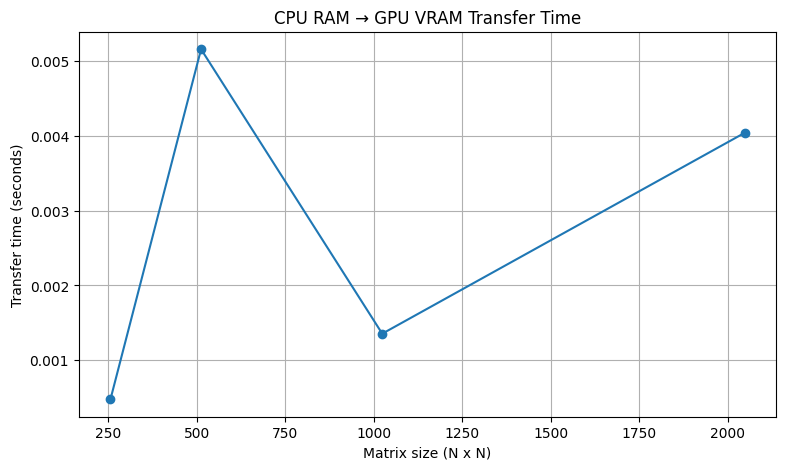

In [ ]:
#13
transfer_results = []
if GPU_AVAILABLE:
    for N in [256, 512, 1024, 2048]:
        A = np.random.rand(N, N).astype(np.float32)
        d_A = cuda.to_device(A)
        cuda.synchronize()
        start = time.perf_counter()
        d_A = cuda.to_device(A)
        cuda.synchronize()
        transfer_time = time.perf_counter() - start
        data_mb = A.nbytes / (1024**2)
        bandwidth = data_mb / transfer_time
        transfer_results.append({
            "N": N,
            "Data (MB)": data_mb,
            "Transfer Time (s)": transfer_time,
            "Effective Bandwidth (MB/s)": bandwidth
        })
    transfer_df = pd.DataFrame(transfer_results)
    display(transfer_df)
    plt.figure(figsize=(9,5))
    plt.plot(transfer_df["N"], transfer_df["Transfer Time (s)"], marker="o")
    plt.xlabel("Matrix size (N x N)")
    plt.ylabel("Transfer time (seconds)")
    plt.title("CPU RAM → GPU VRAM Transfer Time")
    plt.grid(True)
    plt.show()
else:
    print("Transfer benchmark skipped because no GPU is available.")

In [ ]:
#14
TILE = 16
if GPU_AVAILABLE:
    @cuda.jit
    def transpose_gpu_tiled(A, B):
        tile = cuda.shared.array((16, 17), dtype=float32)
        tx = cuda.threadIdx.x
        ty = cuda.threadIdx.y
        row = cuda.blockIdx.y * 16 + ty
        col = cuda.blockIdx.x * 16 + tx
        if row < A.shape[0] and col < A.shape[1]:
            tile[ty, tx] = A[row, col]
        cuda.syncthreads()
        out_row = cuda.blockIdx.x * 16 + ty
        out_col = cuda.blockIdx.y * 16 + tx
        if out_row < B.shape[0] and out_col < B.shape[1]:
            B[out_row, out_col] = tile[tx, ty]
    print("Improved tiled GPU kernel ready.")

Improved tiled GPU kernel ready.


In [ ]:
#15
def run_gpu(A, kernel, block=(16, 16)):
    if not GPU_AVAILABLE:
        return None, np.nan
    d_A = cuda.to_device(A)
    B = np.empty(
        (A.shape[1], A.shape[0]),
        dtype=A.dtype
    )
    d_B = cuda.device_array_like(B)
    grid = (
        math.ceil(A.shape[1] / block[0]),
        math.ceil(A.shape[0] / block[1])
    )
    kernel[grid, block](d_A, d_B)
    cuda.synchronize()
    start = time.perf_counter()
    kernel[grid, block](d_A, d_B)
    cuda.synchronize()
    elapsed = time.perf_counter() - start
    d_B.copy_to_host(B)
    return B, elapsed

In [ ]:
#16
test_sizes = [
    (256, 256),
    (512, 512),
    (1024, 1024),
    (2048, 2048),
    (512, 1024),
    (1024, 512)
]
for rows, cols in test_sizes:
    A = np.random.rand(rows, cols).astype(np.float32)
    B_cpu, _ = run_cpu(A)
    print("\nMatrix size:", rows, "x", cols)
    print("CPU correct:", np.allclose(B_cpu, A.T))
    if GPU_AVAILABLE:
        B_naive, _ = run_gpu(A, transpose_gpu_naive)
        B_tiled, _ = run_gpu(A, transpose_gpu_tiled)
        print("Naive GPU correct:", np.allclose(B_naive, A.T))
        print("Tiled GPU correct:", np.allclose(B_tiled, A.T))


Matrix size: 256 x 256
CPU correct: True
Naive GPU correct: True
Tiled GPU correct: True

Matrix size: 512 x 512
CPU correct: True
Naive GPU correct: True
Tiled GPU correct: True

Matrix size: 1024 x 1024
CPU correct: True
Naive GPU correct: True
Tiled GPU correct: True

Matrix size: 2048 x 2048
CPU correct: True
Naive GPU correct: True
Tiled GPU correct: True

Matrix size: 512 x 1024
CPU correct: True
Naive GPU correct: True
Tiled GPU correct: True

Matrix size: 1024 x 512
CPU correct: True
Naive GPU correct: True
Tiled GPU correct: True


**Improved** **CPU and GPU Benchmark**

In [ ]:
#17
def benchmark_cpu(A, repeats=10):
    B = np.empty(
        (A.shape[1], A.shape[0]),
        dtype=A.dtype
    )
    transpose_cpu(A, B)
    times = []
    for i in range(repeats):
        start = time.perf_counter()
        transpose_cpu(A, B)
        elapsed = time.perf_counter() - start
        times.append(elapsed)
    return B, np.median(times)

In [ ]:
#18
def benchmark_gpu(A, kernel, repeats=10):
    if not GPU_AVAILABLE:
        return None, np.nan
    d_A = cuda.to_device(A)
    B = np.empty(
        (A.shape[1], A.shape[0]),
        dtype=A.dtype
    )
    d_B = cuda.device_array_like(B)
    block = (16, 16)
    grid = (
        math.ceil(A.shape[1] / 16),
        math.ceil(A.shape[0] / 16)
    )
    # Warm-up
    kernel[grid, block](d_A, d_B)
    cuda.synchronize()
    times = []
    for i in range(repeats):
        start = time.perf_counter()
        kernel[grid, block](d_A, d_B)
        cuda.synchronize()
        elapsed = time.perf_counter() - start
        times.append(elapsed)
    d_B.copy_to_host(B)
    return B, np.median(times)

In [ ]:
#19 Final CPU vs GPU Benchmark
sizes = [256, 512, 1024, 2048]
final_results = []
for N in sizes:
    print("Testing:", N, "x", N)
    A = np.random.rand(N, N).astype(np.float32)
    B_cpu, cpu_time = benchmark_cpu(A)
    B_naive, naive_time = benchmark_gpu(
        A, transpose_gpu_naive
    )
    B_tiled, tiled_time = benchmark_gpu(
        A, transpose_gpu_tiled
    )
    final_results.append({
        "Matrix Size": str(N) + "x" + str(N),
        "CPU Time (s)": cpu_time,
        "Naive GPU Time (s)": naive_time,
        "Tiled GPU Time (s)": tiled_time,
        "Naive Speedup": cpu_time / naive_time,
        "Tiled Speedup": cpu_time / tiled_time,
        "Correct": (
            np.allclose(B_cpu, B_naive)
            and np.allclose(B_cpu, B_tiled)
        )
    })
final_df = pd.DataFrame(final_results)
display(final_df)

Testing: 256 x 256
Testing: 512 x 512
Testing: 1024 x 1024
Testing: 2048 x 2048


,Matrix Size,CPU Time (s),Naive GPU Time (s),Tiled GPU Time (s),Naive Speedup,Tiled Speedup,Correct
0,256x256,0.000244,0.000041,0.000041,5.907501,5.964646,True
1,512x512,0.000888,0.000052,0.000050,17.042778,17.800136,True
2,1024x1024,0.004721,0.000116,0.000093,40.581394,50.897804,True
3,2048x2048,0.020433,0.000342,0.000261,59.821299,78.302120,True


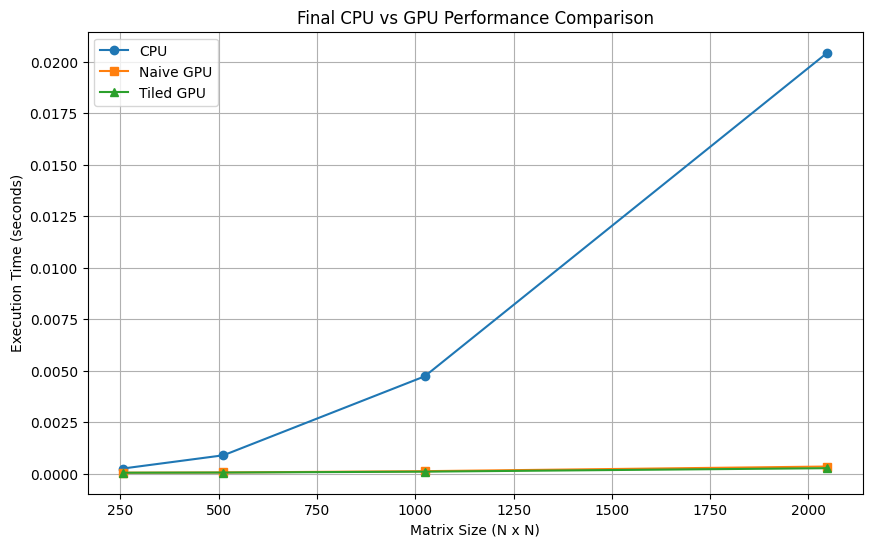

In [ ]:
#20 Final Performance Comparison Graph
plt.figure(figsize=(10, 6))
plt.plot(
    sizes,
    final_df["CPU Time (s)"],
    marker="o",
    label="CPU"
)
plt.plot(
    sizes,
    final_df["Naive GPU Time (s)"],
    marker="s",
    label="Naive GPU"
)
plt.plot(
    sizes,
    final_df["Tiled GPU Time (s)"],
    marker="^",
    label="Tiled GPU"
)
plt.xlabel("Matrix Size (N x N)")
plt.ylabel("Execution Time (seconds)")
plt.title("Final CPU vs GPU Performance Comparison")
plt.legend()
plt.grid(True)
plt.show()

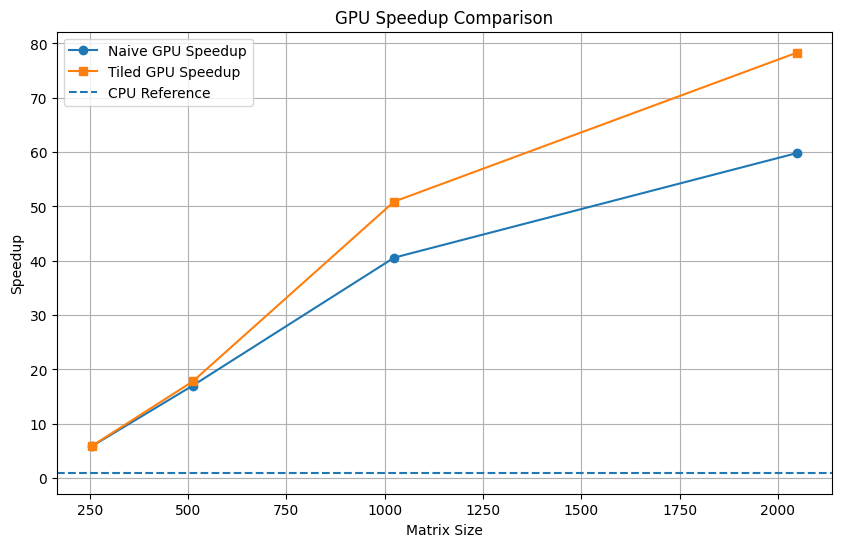

In [ ]:
#21 GPU Speedup Comparison
plt.figure(figsize=(10, 6))
plt.plot(
    sizes,
    final_df["Naive Speedup"],
    marker="o",
    label="Naive GPU Speedup"
)
plt.plot(
    sizes,
    final_df["Tiled Speedup"],
    marker="s",
    label="Tiled GPU Speedup"
)
plt.axhline(
    y=1,
    linestyle="--",
    label="CPU Reference"
)
plt.xlabel("Matrix Size")
plt.ylabel("Speedup")
plt.title("GPU Speedup Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#22 Bidirectional Memory Transfer
transfer_final = []
if GPU_AVAILABLE:
    for N in sizes:
        A = np.random.rand(N, N).astype(np.float32)
        # CPU to GPU
        start = time.perf_counter()
        d_A = cuda.to_device(A)
        cuda.synchronize()
        h2d_time = time.perf_counter() - start
        # GPU to CPU
        B = np.empty_like(A)
        start = time.perf_counter()
        d_A.copy_to_host(B)
        cuda.synchronize()
        d2h_time = time.perf_counter() - start
        transfer_final.append({
            "Matrix Size": N,
            "H2D Time (s)": h2d_time,
            "D2H Time (s)": d2h_time,
            "Total Transfer Time (s)": h2d_time + d2h_time
        })
transfer_df_final = pd.DataFrame(transfer_final)
display(transfer_df_final)

,Matrix Size,H2D Time (s),D2H Time (s),Total Transfer Time (s)
0,256,0.001339,0.000825,0.002163
1,512,0.000556,0.000471,0.001026
2,1024,0.001373,0.001086,0.002459
3,2048,0.005234,0.005798,0.011032


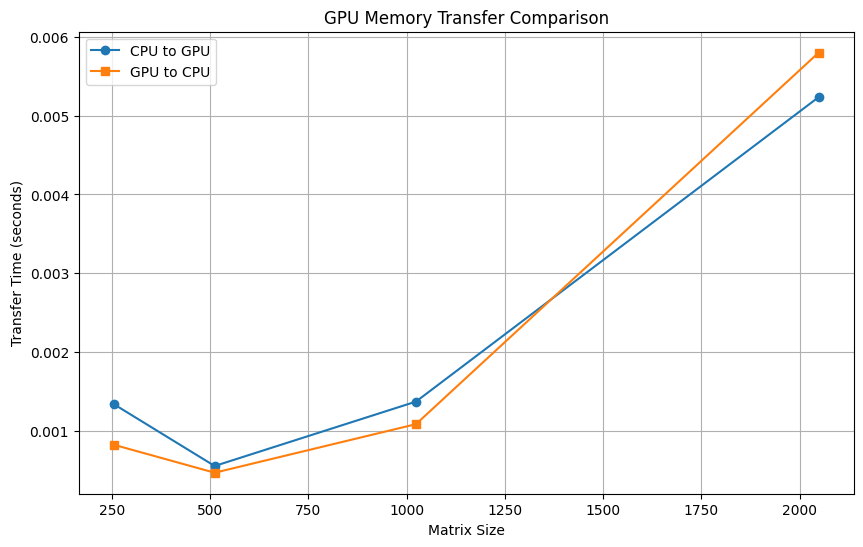

In [ ]:
#23 Memory Transfer Graph
plt.figure(figsize=(10, 6))
plt.plot(
    transfer_df_final["Matrix Size"],
    transfer_df_final["H2D Time (s)"],
    marker="o",
    label="CPU to GPU"
)
plt.plot(
    transfer_df_final["Matrix Size"],
    transfer_df_final["D2H Time (s)"],
    marker="s",
    label="GPU to CPU"
)
plt.xlabel("Matrix Size")
plt.ylabel("Transfer Time (seconds)")
plt.title("GPU Memory Transfer Comparison")
plt.legend()
plt.grid(True)
plt.show()